# Chapter 10 답안: 주문 취소 여부의 이진 분류

## 제출 정보

- 이름: 송누리
- GitHub ID: HauserNR
- 작성일: 2026-11-18
- 최종 Notebook URL: [chapter10/chapter10.ipynb](https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter10/chapter10.ipynb)
- 입력 데이터: 공통 프로젝트의 `data/raw/` 4종
- 최종 판단: **현재 사용 보류**

### 실행 환경과 입력 데이터

실행 환경은 `requirements.txt`를 기준으로 구성했다. 저장소 루트에서 다음 명령으로 의존성을 설치할 수 있다.

```bash
python -m pip install -r requirements.txt
```

공통 Raw 데이터는 고객 150명, 상품 100개, 주문 300건, 주문 상세 764행이다. Raw에서 Processed를 다시 생성하고 PK/FK·중복·필수값·금액을 검증했다. 원본 데이터는 보존했으며 결측 대체·스케일링·인코딩은 Train Pipeline에서만 학습했다.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, tempfile, subprocess

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'ch10_mpl'))
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾을 수 없습니다.')

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
CHAPTER_DIR = PROJECT_ROOT / 'chapter10'
IMAGE_DIR = CHAPTER_DIR / 'images'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

def show_figure(fig, filename):
    fig.savefig(IMAGE_DIR / filename, dpi=150, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)

display(pd.DataFrame([{'Python': platform.python_version(), 'pandas': pd.__version__,
                       'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
                       'matplotlib': matplotlib.__version__, 'seed': 42}]))

from scripts.prepare_ch10_data import prepare_ch10_data
preparation = prepare_ch10_data()
assert not preparation['source_checks']['status'].eq('FAIL').any()
display(pd.read_csv(REPORT_DIR / 'ch10_input_manifest.csv'))
display(preparation['source_checks'])
display(preparation['relationship_checks'])

,Python,pandas,numpy,scikit-learn,matplotlib,seed
0,3.12.0,3.0.5,2.5.3,1.9.1,3.11.1,42


,file,rows,sha256
0,data/raw/customers.csv,150,a663be98960246a436ce7e1ad81284760000ac5ba0d52a...
1,data/raw/products.csv,100,46ff06753ade3e71011ee08dd366148dcd9c36521f1118...
2,data/raw/orders.csv,300,0df461755b933af9f5413427a1c160ca2101b24a5fcd2c...
3,data/raw/order_items.csv,764,a7a5c3942b0886c66cb38cc6a10fdfa68dbcde90e86425...


,check,value,status,resolution
0,customers_primary_key,0,PASS,검증 통과
1,customers_duplicate_rows,0,PASS,검증 통과
2,products_primary_key,0,PASS,검증 통과
3,products_duplicate_rows,0,PASS,검증 통과
4,orders_primary_key,0,PASS,검증 통과
5,orders_duplicate_rows,0,PASS,검증 통과
6,order_items_primary_key,0,PASS,검증 통과
7,order_items_duplicate_rows,0,PASS,검증 통과
8,orders_customer_id_foreign_key,0,PASS,검증 통과
9,order_items_order_id_foreign_key,0,PASS,검증 통과


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


## 1. 분류 문제 정의

- 타깃: `is_cancelled`
- 0의 의미: `completed`(완료)
- 1의 의미: `cancelled`(취소)
- 제외한 상태: `refunded` 및 기타 상태. `refunded`를 0으로 치환하지 않는다.
- 예측 단위: 주문 1건
- 예측 시점: **주문 접수 직후, 최초 주문 상세와 선택 결제수단이 확정·기록됐고 아직 취소/완료 결과가 생기기 전**
- 사용 가능한 정보: 당시 고객 나이·성별·도시, 최초 주문 월·요일·결제수단, 최초 상세의 상품 행 수·총수량·명목 주문금액
- 제외 정보: 최종 상태·Target, 주문/고객/상품 ID·내부 인덱스·이름, 취소 사유·취소 시각·환불/배송 후 정보, 신뢰할 수 없는 가입일 파생 정보

**나의 해석과 판단:** 접수 시점의 취소 위험 선별 가능성을 보려는 문제다. Chapter09에서는 금액 자체가 Target이었지만, 이번에는 취소 여부가 Target이고 상세가 이미 확정된 시점을 가정하므로 주문금액 집계를 입력으로 쓸 수 있다. 금액은 취소·완료 주문의 최초 장바구니 명목 합계이며 실제 매출·결제 완료액은 아니다.

**업무·분석적 의미:** 위험 알림이나 사전 확인 대상을 찾는 보조 분석을 가정한다. 이 점수만으로 주문을 취소하거나 고객을 제재할 근거는 없다.

**한계와 추가 확인:** 주문 당시의 고객 속성 스냅샷, 상세 변경 이력·기록 시각이 없다. 현재 CSV 값이 실제 접수 시점에도 존재했다는 가정은 운영 데이터에서 확인해야 한다. 취소 시각·라벨 관찰 종료일도 없어 '접수 후 7일 이내 취소' 같은 고정 예측 기간과 라벨 성숙 여부는 검증할 수 없다.

In [2]:
from src.classification import load_classification_source_data

data = load_classification_source_data(PROCESSED_DIR)
customers, orders, order_items = (data[k] for k in ['customers', 'orders', 'order_items'])
display(pd.DataFrame([{'table': k, 'rows': len(v), 'columns': len(v.columns)}
                      for k, v in data.items()]))
status_summary = (orders['order_status'].value_counts(dropna=False)
                  .rename_axis('order_status').reset_index(name='order_count'))
status_summary['used_for_binary_target'] = status_summary.order_status.isin(['completed', 'cancelled'])
display(status_summary)
assert int(status_summary.loc[~status_summary.used_for_binary_target, 'order_count'].sum()) == 52

,table,rows,columns
0,customers,150,6
1,orders,300,7
2,order_items,764,6


,order_status,order_count,used_for_binary_target
0,completed,184,True
1,cancelled,64,True
2,refunded,52,False


## 2. Feature Contract와 Leakage Audit

| 구분 | 사용 Feature | 접수 시점 가용성의 근거·가정 |
| --- | --- | --- |
| 숫자형 | `age` | 접수 당시 저장된 나이라고 가정. 현재 나이로 과거 값을 덮어썼다면 재구성 필요 |
| 숫자형 | `item_count`, `total_quantity`, `order_amount` | 최초 주문 상세가 접수 시 확정됐다고 가정 |
| 숫자형 | `order_month`, `order_dayofweek` | 주문일에서 행별로 추출. 전체 데이터의 통계를 학습하지 않음 |
| 범주형 | `gender`, `city` | 접수 당시 고객 정보라고 가정. 이력 없음·공정성 별도 검증 필요 |
| 범주형 | `payment_method` | 선택한 결제수단이며 최종 결제 성공 여부가 아님 |

금지 Feature는 `order_status`, `is_cancelled`, `order_id`, `customer_id`, `product_id`, `source_index`, `name`, `cancel_reason`, `cancelled_at` 및 기타 사후 정보다. 가입일 역전 오류 때문에 `signup_date`, `days_since_signup`도 전체 표본에서 제외한다. 허용 목록 밖의 열은 모델에 전달하지 않는다.

**나의 해석과 판단:** 파일은 결과가 확정된 뒤 내려받은 스냅샷이다. 파일에 값이 존재한다는 사실만으로 과거 접수 시점의 가용성이 입증되지 않는다. Target·상태를 넣으면 정답을 미리 보는 직접 누수가 되고, ID는 고객/주문을 암기하거나 내부 자료를 노출할 수 있다. 가입일의 오류는 Test 성능을 확인하기 전에 처리했다.

**업무·분석적 의미와 한계:** 정확한 시점 조인이 가능한 데이터가 우선이다. 성별·나이·도시를 포함한 것은 공식 교육용 후보를 검토하기 위한 선택이며, 운영 사용의 타당성·집단별 오류율이 검증됐다는 뜻은 아니다.

## 3. 주문 단위 특징과 병합 검증

계산은 `line_total = quantity × unit_price`, `item_count = 상세 행 수`(고유 상품 수가 아님), `total_quantity = 수량 합`, `order_amount = line_total 합`으로 정의한다. `order_item_id`가 다른 동일 상품 행은 독립 상세이므로 무조건 중복 제거하지 않는다.

**계산 불일치 0건, 주문 특징 `order_id` 중복 0건**, 필수값 결측·PK 중복·FK 미매칭 0건을 확인했다. Raw에는 `line_total` 열이 없어 수량·단가로 생성한 뒤 Processed와 재계산값을 대조했다. 외부 영수증 총액과의 대사가 아니라 내부 산식 정합성 검사다.

In [3]:
from src.classification import (
    build_order_item_features, build_classification_dataset,
    build_feature_audit, validate_feature_columns, FORBIDDEN_FEATURES,
    target_distribution,
)

model_data, numeric_features, categorical_features, merge_checks, data_quality_checks = (
    build_classification_dataset(customers, orders, order_items)
)
features = numeric_features + categorical_features
validate_feature_columns(features)
feature_audit = build_feature_audit(numeric_features, categorical_features)
assert not set(features) & FORBIDDEN_FEATURES
assert not {'days_since_signup', 'signup_date'} & set(features)
display(feature_audit)
print('Feature leakage overlap:', len(set(features) & FORBIDDEN_FEATURES))

item_features = build_order_item_features(order_items)
line_mismatch = int((order_items.line_total - order_items.quantity * order_items.unit_price).abs().gt(1e-6).sum())
assert line_mismatch == 0 and item_features.order_id.is_unique
assert np.isclose(item_features.order_amount.sum(), order_items.line_total.sum())
assert item_features.total_quantity.sum() == order_items.quantity.sum()
assert item_features.item_count.sum() == len(order_items)
assert model_data[features].notna().all().all()
assert len(model_data) == 248 and model_data.order_id.is_unique
print('line_total mismatch:', line_mismatch)
print('order feature duplicate keys:', int(item_features.order_id.duplicated().sum()))
print('missing selected feature values:', int(model_data[features].isna().sum().sum()))
display(merge_checks)
display(data_quality_checks)

,column,selected,role,reason
0,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,item_count,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,total_quantity,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,order_amount,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
7,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
8,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
9,cancel_reason,False,forbidden,취소 이후 생성되는 사후 정보


Feature leakage overlap: 0
line_total mismatch: 0
order feature duplicate keys: 0
missing selected feature values: 0


,merge,before_rows,after_rows,row_count_preserved,unmatched_count,relationship,status
0,order_id → order_item_features,248,248,True,0,one_to_one,PASS
1,customer_id → customers,248,248,True,0,many_to_one,PASS


,check_item,count,resolution
0,binary_target_rows,248,validated
1,completed_rows,184,validated
2,cancelled_rows,64,validated
3,excluded_status_rows,52,validated
4,line_total_mismatch,0,validated
5,negative_days_since_signup,34,원본 보존; signup_date·days_since_signup을 전체 Featu...
6,missing_order_item_features,0,validated
7,missing_customer_match,0,validated
8,status_scope:completed,184,NaN
9,status_scope:cancelled,64,NaN


### 병합 결과 관찰

| merge                          | relationship   |   before_rows |   after_rows |   unmatched_count | status   |
|:-------------------------------|:---------------|--------------:|-------------:|------------------:|:---------|
| order_id → order_item_features | one_to_one     |           248 |          248 |                 0 | PASS     |
| customer_id → customers        | many_to_one    |           248 |          248 |                 0 | PASS     |

원본 300주문에서 환불 52건을 제외한 **248건**을 두 병합 모두 보존했다. 고객 150명, 상품 100개, 주문 상세 764행의 공통 원본을 사용했다. 모든 상태의 상세를 먼저 집계하고 Target 범위 주문에 안전하게 연결했다.

### 원본 날짜 문제와 처리

전체 300건 중 가입일이 주문일보다 늦은 주문이 **48건**이다. 분류 범위에서는 완료 **23건**, 취소 **11건**으로 총 **34건**이다. 생성 코드에서 고객 가입일과 주문일을 독립적으로 추출하는 것이 가능한 원인이다. 실제 가입일을 알 수 없어 날짜를 앞당기거나 0으로 치환하지 않았다. 오류가 있는 주문만 삭제하면 클래스 구성과 표본이 바뀌므로 모든 주문을 보존하고 **가입일 관련 Feature를 모든 행에서 제외**했다.

### 나의 해석과 판단

미매칭을 0으로 채우면 실제 '상품 수 0·금액 0' 주문과 데이터 연결 실패가 섞인다. 잘못된 키·누락 원인을 숨겨 모델이 품질 오류를 학습할 수 있으므로 중단 후 원인을 해결해야 한다. 현재 PK/FK·금액·행 수·필수값 검증은 통과했다. 날짜 역전은 원본 품질 검사에서 **WARN으로 남기며**, 해당 Feature를 제외한 모델 입력 계약만 PASS로 판단한다.

### 업무·분석적 의미와 한계

병합 통과는 키 연결과 산식의 정합성을 뜻한다. 주문 상세가 취소 뒤 수정되지 않았는지, 고객 스냅샷이 과거와 일치하는지는 증명하지 않는다. 실제 운영 입력으로 승격하기 전 날짜 원천과 이력 테이블을 정비해야 한다.

## 4. 클래스 비율

취소(`1`)를 Positive로 고정한다. 상태가 완료인 주문만 0으로 정의하며 환불을 완료에 섞지 않는다.

,is_cancelled,class_label,count,ratio
0,0,completed,184,0.7419
1,1,cancelled,64,0.2581


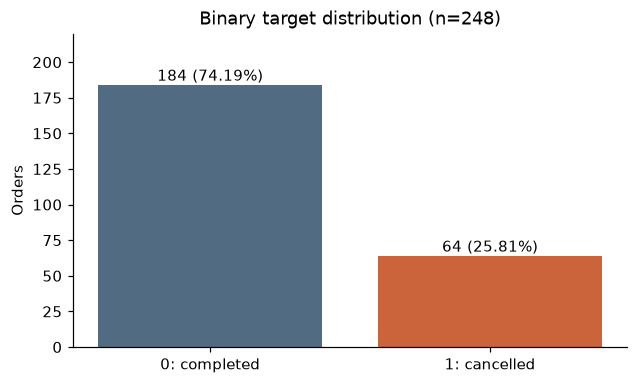

In [4]:
target_dist = target_distribution(model_data)
display(target_dist)
fig, ax = plt.subplots(figsize=(6.5, 3.7))
counts = target_dist['count'].to_numpy()
bars = ax.bar(['0: completed', '1: cancelled'], counts, color=['#516b83', '#cb633b'])
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, count + 3,
            f'{count} ({count / counts.sum():.2%})', ha='center')
ax.set(ylabel='Orders', title='Binary target distribution (n=248)', ylim=(0, 220))
show_figure(fig, 'step02_class_ratio.png')

**결과 관찰:** 완료 184건(**74.19%**), 취소 64건(**25.81%**)이다. 완료가 약 2.88배 많다.

**나의 해석과 판단:** 모든 주문을 완료로 예측해도 전체에서 약 74%의 Accuracy를 얻지만 취소 Recall은 0이다. 불균형이 극단적이지 않아도 Accuracy만 보면 취소 탐지 실패를 놓친다. 그래서 Dummy Most Frequent를 비교 기준으로 둔다.

**업무·분석적 의미와 한계:** 취소를 찾는 목적에 필요한 지표는 취소 클래스의 Precision·Recall·F1이다. 이 클래스 비율은 가상 데이터의 관측 비율이며 실제 사업의 취소율로 일반화할 수 없다.

## 5. Train / Validation / Test 역할

`random_state=42`로 두 번의 stratified random split을 적용했다. 전체의 20%를 Test로 분리하고, 나머지의 25%를 Validation으로 분리해 약 60/20/20 비율을 구성했다.

| Split | 역할 | 클래스 0 | 클래스 1 | 합계 |
| --- | --- | ---: | ---: | ---: |
| Train | 모델·전처리 학습 | 110 | 38 | 148 |
| Validation | 모델·Threshold 선택 | 37 | 13 | 50 |
| Test | 선택 고정 후 최종 평가 | 37 | 13 | 50 |

**나의 해석과 판단:** Test를 보며 모델·임계값을 바꾸면 그 표본의 우연한 패턴에 맞추게 되므로 독립적인 최종 평가가 사라진다. 분할 단계에서는 두 클래스의 존재와 비율만 확인했다. Test 성능은 모델·Threshold 선택에 사용하지 않았다.

**교육용 random split의 한계:** 과거·미래 주문이 섞이고 같은 고객이 여러 분할에 등장할 수 있다. 따라서 새로운 미래 주문이나 미관측 고객의 성능을 보장하지 않는다. 실제 운영 전에는 시간순 Train/Validation/Test, 충분한 관찰 기간을 둔 out-of-time 평가, 신규 고객이 목적이면 고객 그룹 분리를 추가해야 한다.

In [5]:
from src.classification import split_train_validation_test, build_split_summary

(X_train, X_valid, X_test, y_train, y_valid, y_test, features) = split_train_validation_test(
    model_data, numeric_features, categorical_features, random_state=42,
)
split_summary = build_split_summary(y_train, y_valid, y_test)
display(split_summary)
split_indices = [set(frame.index) for frame in [X_train, X_valid, X_test]]
assert not (split_indices[0] & split_indices[1] or split_indices[0] & split_indices[2]
            or split_indices[1] & split_indices[2])
assert set.union(*split_indices) == set(model_data.index)
assert all(set(y.unique()) == {0, 1} for y in [y_train, y_valid, y_test])
customer_sets = [set(model_data.loc[x.index, 'customer_id']) for x in [X_train, X_valid, X_test]]
display(pd.DataFrame([
    {'pair': label, 'shared_customer_count': len(customer_sets[a] & customer_sets[b])}
    for label, a, b in [('train-validation', 0, 1), ('train-test', 0, 2), ('validation-test', 1, 2)]
]))
print('Order-level disjoint and complete split: PASS')

,split,is_cancelled,class_label,count,ratio
0,train,0,completed,110,0.7432
1,train,1,cancelled,38,0.2568
2,validation,0,completed,37,0.7400
3,validation,1,cancelled,13,0.2600
4,test,0,completed,37,0.7400
5,test,1,cancelled,13,0.2600


,pair,shared_customer_count
0,train-validation,32
1,train-test,25
2,validation-test,11


Order-level disjoint and complete split: PASS


## 6. Dummy Baseline과 Validation 모델 비교

숫자형은 `SimpleImputer(median) → StandardScaler`, 범주형은 `SimpleImputer(most_frequent) → OneHotEncoder(handle_unknown="ignore")`로 전처리했다. 이를 `ColumnTransformer`와 모델 `Pipeline`에 넣고, 각 후보를 **Train 148건으로만 fit**했다. Validation/Test에는 학습된 전처리와 모델을 적용했다. 공통 전처리는 문자열·날짜·수치 변환과 행별 계산만 수행하며 전체 데이터로 결측값 통계를 학습하지 않는다.

비교한 모델은 Dummy Most Frequent, Logistic Regression(`max_iter=1000`, `class_weight='balanced'`), Random Forest(`n_estimators=200`, `random_state=42`, `class_weight='balanced'`)다. 기본 Threshold 0.50의 Validation 결과를 비교한 후, 비Dummy 후보 중 **F1 → Recall → Precision → 모델명** 순으로 선택했다. Test 결과와 무관하게 정한 규칙이다. class weight는 학습 표본의 소수 클래스 가중을 높이는 설정이며 실제 오류 비용을 추정한 값은 아니다.

,model,evaluation_split,accuracy,precision,recall,f1
0,Logistic Regression,validation,0.5400,0.2500,0.3846,0.3030
1,Random Forest,validation,0.6600,0.3000,0.2308,0.2609
2,Dummy Most Frequent,validation,0.7400,0.0000,0.0000,0.0000


Selected on validation: Logistic Regression


,model,fit_rows,train_only_preprocessing
0,Dummy Most Frequent,148,PASS
1,Logistic Regression,148,PASS
2,Random Forest,148,PASS


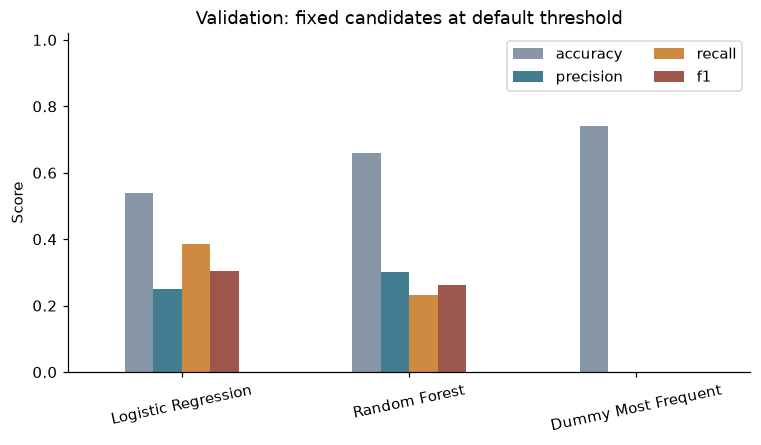

In [6]:
from src.classification import train_and_compare_on_validation, select_validation_model

models, validation_comparison, validation_predictions, validation_probabilities = (
    train_and_compare_on_validation(X_train, X_valid, y_train, y_valid,
                                    numeric_features, categorical_features, random_state=42)
)
selected_model_name = select_validation_model(validation_comparison)
selected_model = models[selected_model_name]
display(validation_comparison)
print('Selected on validation:', selected_model_name)

preprocessing_checks = []
for name, fitted in models.items():
    pre = fitted.named_steps['preprocessor']
    num = pre.named_transformers_['num']
    expected_median = X_train[numeric_features].median().to_numpy()
    assert np.allclose(num.named_steps['imputer'].statistics_, expected_median)
    train_imputed = num.named_steps['imputer'].transform(X_train[numeric_features])
    assert np.allclose(num.named_steps['scaler'].mean_, train_imputed.mean(axis=0))
    assert np.all(np.asarray(num.named_steps['scaler'].n_samples_seen_) == len(X_train))
    cat = pre.named_transformers_['cat']
    train_cat = cat.named_steps['imputer'].transform(X_train[categorical_features])
    assert all(set(values) == set(train_cat[:, j])
               for j, values in enumerate(cat.named_steps['onehot'].categories_))
    preprocessing_checks.append({'model': name, 'fit_rows': len(X_train),
                                 'train_only_preprocessing': 'PASS'})
display(pd.DataFrame(preprocessing_checks))
fig, ax = plt.subplots(figsize=(8, 4))
plot_data = validation_comparison.set_index('model')[['accuracy', 'precision', 'recall', 'f1']]
plot_data.plot.bar(ax=ax, color=['#8897a7', '#427d92', '#cf8a41', '#9c574c'], rot=12)
ax.set(ylabel='Score', ylim=(0, 1.02), xlabel='', title='Validation: fixed candidates at default threshold')
ax.legend(loc='upper right', ncol=2)
show_figure(fig, 'step03_baseline.png')

### 결과 관찰

| model               |   accuracy |   precision |   recall |     f1 |
|:--------------------|-----------:|------------:|---------:|-------:|
| Logistic Regression |     0.5400 |      0.2500 |   0.3846 | 0.3030 |
| Random Forest       |     0.6600 |      0.3000 |   0.2308 | 0.2609 |
| Dummy Most Frequent |     0.7400 |      0.0000 |   0.0000 | 0.0000 |

Validation에서 선택한 모델은 **Logistic Regression**이다. Threshold 0.50에서 F1 0.3030, Recall 0.3846으로 Random Forest의 F1 0.2609, Recall 0.2308보다 높다. Accuracy는 Dummy의 0.7400이 가장 높다. Dummy는 취소로 예측한 주문이 없어 Precision이 정의되지 않는다. 비교표에는 코드의 `zero_division=0` 규칙에 따라 0으로 표시했다.

### 나의 해석과 판단

Logistic Regression은 Dummy가 놓친 취소 중 일부를 찾지만 Accuracy는 0.5400으로 낮아졌다. 취소 Precision 0.2500은 Validation의 취소율 0.2600보다 낮아, 알림 대상에서 취소 비중이 높아졌다는 증거도 부족하다. **Dummy 대비 F1이 0에서 증가했다는 사실만으로 유용한 모델이라고 판단할 수 없다.**

### 업무·분석적 의미 및 한계

F1은 TN을 반영하지 않으며 FP/FN의 경제적 비용도 모른다. 세 고정 후보만 비교했으며 별도의 하이퍼파라미터 탐색은 하지 않았다. 전처리 통과·class weight 설정도 성능 개선을 보장하지 않는다.

## 7. Validation 성능과 우선 지표

선택 모델의 기본 Threshold 0.50 결과는 Accuracy **0.5400**, Precision **0.2500**, Recall **0.3846**, F1 **0.3030**이다.

- Accuracy = `(TP+TN)/전체`: 전체 정답률
- Precision = `TP/(TP+FP)`: 취소 알림 중 실제 취소 비율
- Recall = `TP/(TP+FN)`: 실제 취소 중 탐지 비율
- F1 = `2×Precision×Recall/(Precision+Recall)`: Precision과 Recall의 조화평균

**가장 중요하게 본 지표와 이유:** 실제 비용 정보가 없어 취소 F1을 우선 지표로 정하고 Recall·Precision을 함께 비교했다. 취소 위험을 먼저 살펴보는 목적에서는 FN을 줄이는 것을 우선 관심사로 **가정**하지만, 이것이 'FN 비용이 FP보다 크다'는 확정이나 Recall만 최대화한다는 뜻은 아니다. 한 번의 알림이 비싸면 다른 목적함수가 필요하다.

**한계와 추가 확인:** class_weight를 사용한 확률은 실제 취소율에 맞춰 보정된 확률이라고 보장할 수 없다. 0.20은 실제 취소율 20%를 뜻하는 검증된 위험 등급이 아니라 현재 모델 점수의 의사결정 기준이다. 확률 보정·PR 곡선·업무 처리 용량은 별도 미래 검증 과제로 남긴다.

## 8. Threshold 비교와 Test 이전 선택 고정

사전에 정한 **0.20~0.80, 0.05 간격**에서 선택 모델의 Validation 확률을 평가했다. F1 → Recall → Precision → 낮은 Threshold 순으로 선택했다. 점수가 Threshold 이상이면 취소 위험(1)이다.

,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp
0,0.2000,0.3200,0.2439,0.7692,0.3704,6,31,3,10
1,0.2500,0.3600,0.2432,0.6923,0.3600,9,28,4,9
2,0.3000,0.3800,0.2353,0.6154,0.3404,11,26,5,8
3,0.3500,0.4400,0.2581,0.6154,0.3636,14,23,5,8
4,0.4000,0.4600,0.2308,0.4615,0.3077,17,20,7,6
5,0.4500,0.5400,0.2727,0.4615,0.3429,21,16,7,6
6,0.5000,0.5400,0.2500,0.3846,0.3030,22,15,8,5
7,0.5500,0.5800,0.2778,0.3846,0.3226,24,13,8,5
8,0.6000,0.6200,0.2857,0.3077,0.2963,27,10,9,4
9,0.6500,0.6400,0.3077,0.3077,0.3077,28,9,9,4


,selection_item,value,selected_on,criterion
0,model,Logistic Regression,validation,f1 → recall → precision
1,threshold,0.2000,validation,f1 → recall → precision → lower threshold


Validation at selected threshold:


,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp
0,0.2000,0.3200,0.2439,0.7692,0.3704,6.0000,31.0000,3.0000,10.0000


Frozen BEFORE test: Logistic Regression 0.2


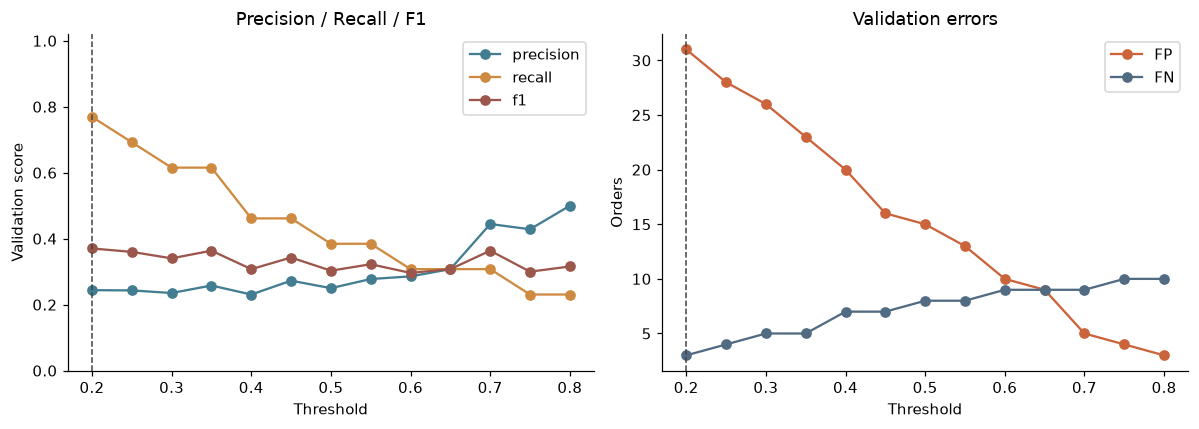

In [7]:
from src.classification import threshold_metrics, choose_threshold, build_selection_summary, freeze_selection

validation_proba = validation_probabilities[selected_model_name]
threshold_df = threshold_metrics(y_valid, validation_proba)
selected_threshold = choose_threshold(threshold_df)
selected_valid_row = threshold_df.loc[np.isclose(threshold_df.threshold, selected_threshold)].iloc[0]
selection_summary = build_selection_summary(selected_model_name, selected_threshold,
                                             validation_comparison, threshold_df)
display(threshold_df)
display(selection_summary)
print('Validation at selected threshold:')
display(pd.DataFrame([selected_valid_row]))

# No test features, labels or metrics are passed to freeze_selection.
frozen_selection = freeze_selection(selected_model_name, selected_threshold,
                                    selected_model, features, REPORT_DIR)
frozen_model_digest = hashlib.sha256(joblib.hash(selected_model).encode()).hexdigest()
assert frozen_model_digest == frozen_selection['fitted_pipeline_sha256']
print('Frozen BEFORE test:', frozen_selection['model'], frozen_selection['threshold'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for metric, color in [('precision', '#427d92'), ('recall', '#cf8a41'), ('f1', '#9c574c')]:
    axes[0].plot(threshold_df.threshold, threshold_df[metric], 'o-', label=metric, color=color)
axes[0].set(xlabel='Threshold', ylabel='Validation score', ylim=(0, 1.02), title='Precision / Recall / F1')
axes[0].legend()
for metric, color in [('fp', '#cb633b'), ('fn', '#516b83')]:
    axes[1].plot(threshold_df.threshold, threshold_df[metric], 'o-', label=metric.upper(), color=color)
axes[1].set(xlabel='Threshold', ylabel='Orders', title='Validation errors')
axes[1].legend()
for ax in axes:
    ax.axvline(selected_threshold, color='#444444', linestyle='--', linewidth=1)
fig.tight_layout()
show_figure(fig, 'step05_threshold.png')

### 결과 관찰과 선택 이유

| Threshold | Accuracy | Precision | Recall | F1 | FP | FN | 예상 특징·관측 결과 |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: | --- |
| **0.20** | 0.3200 | 0.2439 | 0.7692 | **0.3704** | 31 | 3 | 비교 범위에서 F1 최대, 알림 41/50건 |
| 0.50 | 0.5400 | 0.2500 | 0.3846 | 0.3030 | 15 | 8 | 기본값, 취소 13건 중 5건 탐지 |
| 0.70 | 0.7200 | 0.4444 | 0.3077 | 0.3636 | 5 | 9 | 알림은 줄지만 취소 9건 누락 |
| 0.80 | 0.7400 | 0.5000 | 0.2308 | 0.3158 | 3 | 10 | 정밀도 상승, 취소 대부분 누락 |

**선택 Threshold는 0.20**이다. Validation F1 0.3704가 비교한 13개 값 중 최대여서 선택했다. 0.50보다 Recall은 0.3846에서 0.7692로 높아지고 FN은 8건에서 3건으로 줄지만, FP는 15건에서 31건으로 늘었다. Precision은 단조롭게 변하지 않는다. 낮추면 일반적으로 Recall·FP가 늘어날 수 있지만 Precision은 데이터에 따라 오르내릴 수 있다.

**나의 해석과 판단:** 0.70의 F1 0.3636과 차이가 작고 업무 비용은 알 수 없다. 따라서 0.20은 현재 범위와 F1 규칙에서의 교육용 선택이다. 더 낮은 Threshold를 살피지 않았으며 범위 경계가 선택됐다는 한계가 있다. Test 평가 이후에도 탐색 범위와 Threshold를 유지했다. 추가 탐색의 효과는 별도의 독립 자료로 평가해야 한다.

**업무·분석적 의미:** Validation 50건 중 41건(82%)에 알림이 발생한다. 대상을 크게 줄이지 못하고 Precision도 24.39%이므로 실용적인 선별 성능이 확인됐다고 보기 어렵다. 단순히 전부 취소로 표시하는 진단 기준의 Validation F1도 `2×13/(50+13)=0.4127`이다. 이 산술 기준과 비교해도 현재 선택 F1 0.3704는 낮다.

**Test 독립성:** 모델과 Threshold를 Validation에 맞춰 선택했으므로 Validation 성능에는 선택에 따른 낙관성이 포함될 수 있다. 이를 별도의 Test에서 평가했고, Test 결과로 선택을 바꾸지 않았다.

## 9. Final Test: 고정 모델과 Threshold 평가

Validation에서 선택한 **Logistic Regression / Threshold 0.20**을 고정한 뒤 Test를 평가했다. Train+Validation 재학습은 하지 않았다. 재학습으로 확률 분포가 달라지면 기존 Threshold의 근거도 다시 검증해야 하기 때문이다.

In [8]:
from src.classification import final_test_evaluation, confusion_matrix_dataframe, classification_report_dataframe

assert selected_model_name == frozen_selection['model']
assert selected_threshold == frozen_selection['threshold']
assert features == frozen_selection['features']
assert hashlib.sha256(joblib.hash(selected_model).encode()).hexdigest() == frozen_model_digest

# One frozen model/threshold pair; no other candidate is evaluated on final test.
y_pred_test, y_proba_test, test_metrics = final_test_evaluation(
    selected_model, X_test, y_test, threshold=selected_threshold, model_name=selected_model_name,
)
assert hashlib.sha256(joblib.hash(selected_model).encode()).hexdigest() == frozen_model_digest
confusion_df = confusion_matrix_dataframe(y_test, y_pred_test)
classification_report_df = classification_report_dataframe(y_test, y_pred_test)
display(test_metrics)
display(confusion_df)
display(classification_report_df)
tn, fp, fn, tp = confusion_df.to_numpy().ravel().astype(int)
display(pd.DataFrame([{'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp, 'n': len(y_test)}]))
assert tn + fp + fn + tp == len(y_test)
assert np.isclose(test_metrics.iloc[0].precision, tp / (tp + fp))
assert np.isclose(test_metrics.iloc[0].recall, tp / (tp + fn))

valid_final_comparison = pd.DataFrame([
    {'split': 'Validation, threshold=0.20', **selected_valid_row[['accuracy', 'precision', 'recall', 'f1']].to_dict()},
    {'split': 'Final Test, threshold=0.20', **test_metrics.iloc[0][['accuracy', 'precision', 'recall', 'f1']].to_dict()},
])
display(valid_final_comparison)

,model,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
0,Logistic Regression,test_final,0.2000,frozen_before_test,0.3400,0.2727,0.9231,0.4211


,pred_completed,pred_cancelled
actual_completed,5,32
actual_cancelled,1,12


,label,precision,recall,f1-score,support
0,completed,0.8333,0.1351,0.2326,37
1,cancelled,0.2727,0.9231,0.4211,13
2,macro avg,0.5530,0.5291,0.3268,50
3,weighted avg,0.6876,0.3400,0.2816,50


,TN,FP,FN,TP,n
0,5,32,1,12,50


,split,accuracy,precision,recall,f1
0,"Validation, threshold=0.20",0.3200,0.2439,0.7692,0.3704
1,"Final Test, threshold=0.20",0.3400,0.2727,0.9231,0.4211


### 결과 관찰

| 분할 / 고정 모델 | Accuracy | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: |
| Validation / Logistic Regression, 0.20 | 0.3200 | 0.2439 | 0.7692 | 0.3704 |
| Final Test / Logistic Regression, 0.20 | **0.3400** | **0.2727** | **0.9231** | **0.4211** |
| Test 다수 클래스 산술 기준(모두 완료) | 0.7400 | 0.0000* | 0.0000 | 0.0000 |

`*` 취소 예측이 없어 정의되지 않는 Precision을 비교 편의상 0으로 표시했다. Test에서 다른 후보를 새로 학습·선택한 결과가 아니라 사전에 고정한 다수 클래스 규칙의 산술값이다.

고정 Threshold에서 Validation 대비 Accuracy **+0.0200**, Precision **+0.0288**, Recall **+0.1538**, F1 **+0.0507**이다. Test의 혼동행렬은 **TN=5, FP=32, FN=1, TP=12**다. 취소 13건 중 12건을 찾았지만, 완료 37건 중 32건을 잘못 경고했다. 총 50건 중 44건(88%)을 위험으로 분류했고 경고의 72.73%는 FP다.

### 나의 해석과 판단

이번 Test 성능은 Validation보다 떨어지지 않았다. 그러나 두 분할 모두 각 50건·취소 13건으로 작고, 취소 한 건 차이만으로 Recall이 약 0.0769 변한다. 우연한 표본 구성, 같은 고객의 재등장, Validation 기반 선택의 불확실성이 있어 Test의 소폭 상승을 안정적인 일반화 증거로 단정하지 않는다. Precision 0.2727은 Test 취소율 0.2600에 가깝고, 모두 취소 예측의 F1 산술값 0.4127과도 큰 차이가 없다.

### 업무·분석적 의미 및 한계

대부분 주문에 알림을 내면 Recall이 높아져도 검토 업무를 줄이는 이점이 작다. 현 결과는 운영 가치를 입증하지 못했다. 만약 다른 미래 기간에서 성능이 낮아진다면 표본 변동·분포 변화·시점 불일치·라벨 관찰 기간 차이를 확인해야 하며, 같은 Test를 재활용해 선택을 고치지 않는다.

### 선택 보호 확인

- ☑ Test 결과를 보기 전에 모델을 고정했다.
- ☑ Test 결과를 보기 전에 Threshold를 고정했다.
- ☑ Test 결과를 본 뒤 같은 Test를 이용해 Feature·모델·Threshold·분할 규칙을 바꾸지 않았다.

Notebook과 스크립트는 동일한 조건으로 재실행해 재현성을 확인했다. 각 실행에서 모델과 Threshold를 고정한 뒤 한 후보만 Test로 평가했으며, 재실행 결과로 선택을 변경하지 않았다. 이 재실행은 새로운 독립 평가에 해당하지 않는다.

## 10. FP/FN 해석과 오류 분석

| 구분 | 의미 | 이번 Test | 발생할 수 있는 업무 영향(가정) |
| --- | --- | ---: | --- |
| TN | 완료 주문을 완료로 예측 | 5 | 불필요한 확인 없이 정상 처리 |
| FP | 완료 주문을 취소 위험으로 잘못 예측 | 32 | 불필요한 상담·검토, 고객 연락 부담, 인센티브를 지급한다면 불필요한 혜택 비용 |
| FN | 취소 주문을 완료로 잘못 예측 | 1 | 취소 위험 사전 확인·재고/작업 조정 기회 등을 놓칠 가능성 |
| TP | 취소 주문을 취소 위험으로 예측 | 12 | 위험 주문을 포착했으나 실제 개입으로 취소를 예방할 수 있는지는 별도 문제 |

**현재 목적에서 더 부담스러울 수 있는 오류:** 위험 누락을 줄이는 탐색 목적에서는 FN을 우선 관심사로 둔다. 하지만 현재 FP가 32건으로 많아 연락·검토가 비싼 업무에서는 FP가 더 부담스러울 수 있다. 따라서 어느 비용이 더 큰지 확정하지 않는다.

**추가로 필요한 업무 정보:** 알림 1건당 처리 시간·단가, 일일 처리 가능량, 잘못된 연락의 불편·이탈 가능성, 주문별 마진·재고/배송 진행 상태, 취소 사유·시각, 실제 개입의 성공률·실험 결과, 개입하지 않았을 때의 손실, 집단별 FP/FN 차이가 필요하다. 예측된 취소 건수만으로 예방 가능한 매출을 산정할 수는 없다.

**업무·분석적 의미:** Validation에서 선택한 Threshold는 비용 최적값이 아니다. 단순화하면 이번 Test의 오류 부담을 `32×FP 1건 비용 + 1×FN 1건 비용`으로 표현할 수 있지만 비용의 크기·개입 효과·고객별 차이가 없어 금액을 계산하지 않는다.

**한계와 추가 확인:** 오류군별 확률 요약은 모델 출력에 대한 기술통계다. 오류 원인이나 취소 원인을 밝히는 인과 분석이 아니다.

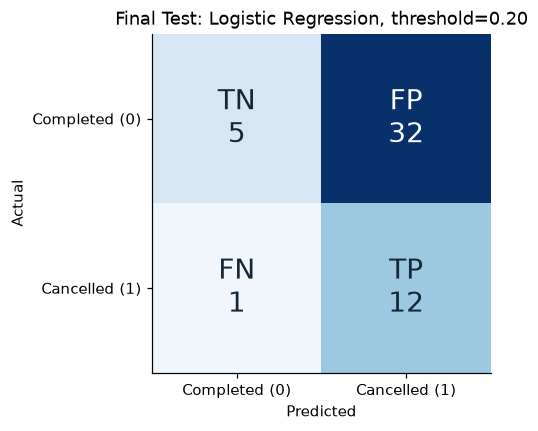

,error_type,count,mean_probability,min_probability,max_probability
0,FN,1,0.0666,0.0666,0.0666
1,FP,32,0.5404,0.2164,0.8767
2,TN,5,0.1715,0.1479,0.1966
3,TP,12,0.5608,0.2602,0.9219


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.imshow(confusion_df.to_numpy(), cmap='Blues', vmin=0)
labels = np.array([['TN', 'FP'], ['FN', 'TP']])
for i in range(2):
    for j in range(2):
        value = int(confusion_df.iloc[i, j])
        ax.text(j, i, f'{labels[i, j]}' + chr(10) + str(value), ha='center', va='center',
                fontsize=18, color='white' if value > 20 else '#152637')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Completed (0)', 'Cancelled (1)'],
       yticklabels=['Completed (0)', 'Cancelled (1)'], xlabel='Predicted', ylabel='Actual',
       title=f'Final Test: {selected_model_name}, threshold={selected_threshold:.2f}')
show_figure(fig, 'step06_confusion_matrix.png')

error_labels = np.select([(y_test.to_numpy() == 0) & (y_pred_test == 1),
                          (y_test.to_numpy() == 1) & (y_pred_test == 0),
                          (y_test.to_numpy() == 1) & (y_pred_test == 1)],
                         ['FP', 'FN', 'TP'], default='TN')
error_summary = (pd.DataFrame({'error_type': error_labels, 'cancel_probability': y_proba_test})
                 .groupby('error_type', as_index=False)
                 .agg(count=('cancel_probability', 'size'),
                      mean_probability=('cancel_probability', 'mean'),
                      min_probability=('cancel_probability', 'min'),
                      max_probability=('cancel_probability', 'max')))
display(error_summary)
error_summary.to_csv(REPORT_DIR / 'ch10_error_summary.csv', index=False)

## 11. Internal / Public 결과 구분

공개 Prediction은 다음 6개 열로 구성했다.

```text
record_id
actual_is_cancelled
predicted_is_cancelled
cancel_probability
model
threshold
```

`record_id`는 Test 출력 순서에 붙인 새 이름이다. 원본 ID·원본 인덱스로부터 생성하지 않는다. 공개 자료에는 `source_index`, `order_id`, `customer_id`, `product_id`를 넣지 않는다. 내부 진단 CSV만 원본 추적 정보를 가질 수 있고 `.gitignore`로 제외한다.

**나의 해석과 판단:** 내부 자료는 오류 원본을 조사하는 데 필요하지만 공개 평가표는 실제/예측/점수만으로 충분하다. 가상 데이터에서도 동일한 공개 원칙을 적용한다. 이 열 제거만으로 실제 개인 데이터의 완전한 익명성이나 재식별 불가능성이 보장되지는 않는다.

In [10]:
from src.classification import create_prediction_result, public_prediction_result

prediction_result_internal = create_prediction_result(
    y_test, y_pred_test, y_proba_test, model_name=selected_model_name,
    threshold=selected_threshold, source_index=X_test.index,
)
prediction_result = public_prediction_result(prediction_result_internal)
public_columns = ['record_id', 'actual_is_cancelled', 'predicted_is_cancelled',
                  'cancel_probability', 'model', 'threshold']
assert prediction_result.columns.tolist() == public_columns
assert not {'order_id', 'customer_id', 'product_id', 'source_index'} & set(prediction_result)
print('Public prediction columns:', prediction_result.columns.tolist())
display(prediction_result.head(10).reset_index(drop=True))
# Error examples also use only public-safe columns and fresh record IDs.
public_errors = prediction_result.assign(error_type=error_labels)
display(public_errors.loc[public_errors.error_type.isin(['FP', 'FN'])]
        .groupby('error_type', sort=True).head(3).reset_index(drop=True))

Public prediction columns: ['record_id', 'actual_is_cancelled', 'predicted_is_cancelled', 'cancel_probability', 'model', 'threshold']


,record_id,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold
0,test_0001,0,1,0.4714,Logistic Regression,0.2000
1,test_0002,0,1,0.5710,Logistic Regression,0.2000
2,test_0003,0,0,0.1693,Logistic Regression,0.2000
3,test_0004,0,1,0.8260,Logistic Regression,0.2000
4,test_0005,0,1,0.6039,Logistic Regression,0.2000
5,test_0006,1,1,0.9219,Logistic Regression,0.2000
6,test_0007,0,0,0.1966,Logistic Regression,0.2000
7,test_0008,0,1,0.6783,Logistic Regression,0.2000
8,test_0009,1,1,0.6549,Logistic Regression,0.2000
9,test_0010,0,1,0.7664,Logistic Regression,0.2000


,record_id,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold,error_type
0,test_0001,0,1,0.4714,Logistic Regression,0.2000,FP
1,test_0002,0,1,0.5710,Logistic Regression,0.2000,FP
2,test_0004,0,1,0.8260,Logistic Regression,0.2000,FP
3,test_0021,1,0,0.0666,Logistic Regression,0.2000,FN


## 12. Validation Evidence와 검토 기록

자동 검증으로 Target 매핑, 금지 Feature 포함 여부, 병합 정합성, 분할 중복·누락, Feature 품질과 가입일 제외 조치, Validation 선택 규칙, 공개 식별자 제거, Final Test의 고정 조건을 확인했다.

**자동 PASS가 의미하지 않는 것:** 운영 적합성, 고객 집단별 공정성, 확률 보정, 시점별 성능 안정성, 실제 취소 원인·개입 효과는 이 검사만으로 보장되지 않는다. 원본의 가입일 역전 WARN도 계속 남는다.

In [11]:
from src.classification import (
    build_classification_validation, build_classification_checklist, save_classification_outputs,
)

validation = build_classification_validation(
    model_data=model_data, features=features, merge_checks=merge_checks,
    y_train=y_train, y_valid=y_valid, y_test=y_test,
    validation_comparison=validation_comparison, selected_model_name=selected_model_name,
    threshold_df=threshold_df, selected_threshold=selected_threshold,
    test_metrics=test_metrics, prediction_result_public=prediction_result,
)
assert validation.status.eq('PASS').all()
classification_checklist = build_classification_checklist(
    CHAPTER_DIR / 'reports/ch10_human_review.csv'
)
output_paths = save_classification_outputs(
    model_data=model_data, target_dist=target_dist, feature_audit=feature_audit,
    merge_checks=merge_checks, data_quality_checks=data_quality_checks, split_summary=split_summary,
    validation_comparison=validation_comparison, threshold_df=threshold_df, test_metrics=test_metrics,
    prediction_result_internal=prediction_result_internal, prediction_result_public=prediction_result,
    confusion_df=confusion_df, report_df=classification_report_df, validation=validation,
    checklist=classification_checklist, selected_model_name=selected_model_name,
    selected_threshold=selected_threshold, report_dir=REPORT_DIR,
)
display(validation)
print(f'Automatic classification validation: {len(validation)}/{len(validation)} PASS')
print('Raw source chronology warning: 48 orders; excluded from model features, NOT repaired.')
display(pd.DataFrame([{'evidence': p.name, 'exists': p.exists(), 'bytes': p.stat().st_size,
                      'scope': 'internal (gitignored)' if '_internal' in p.name else 'public'}
                     for p in output_paths.values()]))

# Export the review record with the evidence sections recorded for this submission.
reviewed_checklist = classification_checklist.copy()
display(reviewed_checklist)
reviewed_checklist.to_csv(CHAPTER_DIR / 'reports/ch10_human_review.csv', index=False)

,check,value,status
0,target_exactly_completed_cancelled,"[0, 1]",PASS
1,split_disjoint_complete,True,PASS
2,required_feature_quality_and_date_mitigation,True,PASS
3,forbidden_feature_overlap,0,PASS
4,merge_rows_and_matches,True,PASS
5,all_splits_have_both_classes,True,PASS
6,model_selected_on_validation,True,PASS
7,threshold_selected_on_validation,True,PASS
8,public_prediction_identifier_columns,none,PASS
9,test_used_as_final_evaluation,True,PASS


Automatic classification validation: 10/10 PASS
Raw source chronology warning: 48 orders; excluded from model features, NOT repaired.


,evidence,exists,bytes,scope
0,ch10_classification_model_data_internal.csv,True,11718,internal (gitignored)
1,ch10_target_distribution.csv,True,85,public
2,ch10_feature_audit.csv,True,1559,public
3,ch10_merge_checks.csv,True,210,public
4,ch10_data_quality_checks.csv,True,450,public
5,ch10_split_summary.csv,True,215,public
6,ch10_validation_model_comparison.csv,True,257,public
7,ch10_validation_threshold_metrics.csv,True,1004,public
8,ch10_test_metrics.csv,True,199,public
9,ch10_classification_predictions_internal.csv,True,3151,internal (gitignored)


,check_item,status,evidence_section
0,completed와 cancelled만 사용해 이진 타깃을 만들었는가?,REVIEWED,1
1,refunded 등 다른 상태를 0 클래스에 섞지 않았는가?,REVIEWED,1
2,예측 시점과 feature 가용성 가정을 설명할 수 있는가?,REVIEWED,2
3,line_total = quantity × unit_price를 검증했는가?,REVIEWED,3
4,병합에 validate를 사용하고 미매칭 0건을 확인했는가?,REVIEWED,3
5,"order_status, target, ID, 사후 정보를 feature에서 제외했는가?",REVIEWED,2
6,"train, validation, test를 분리했는가?",REVIEWED,5
7,모델과 threshold는 validation에서 선택했는가?,REVIEWED,6/8
8,모델과 threshold를 고정한 뒤 test를 한 번만 사용했는가?,REVIEWED,8/9
9,Dummy 기준 모델과 비교했는가?,REVIEWED,6


### 확인한 Evidence

- ☑ `ch10_target_distribution.csv`
- ☑ `ch10_feature_audit.csv`
- ☑ `ch10_merge_checks.csv`
- ☑ `ch10_data_quality_checks.csv`
- ☑ `ch10_split_summary.csv`
- ☑ `ch10_validation_model_comparison.csv`
- ☑ `ch10_validation_threshold_metrics.csv`
- ☑ `ch10_test_metrics.csv`
- ☑ `ch10_confusion_matrix.csv`
- ☑ `ch10_classification_validation.csv`
- ☑ 추가: `ch10_classification_predictions.csv`, `ch10_classification_summary.md`, `ch10_selection_frozen.json`, `ch10_source_checks.csv`, `ch10_input_manifest.csv`

**결과 관찰:** 분류 계약의 자동 Validation은 **10/10 PASS**다. 원본 날짜 검사는 WARN이며 가입일 Feature 제외를 검증했다. 검토 체크리스트에는 항목별 근거 절을 기록했다.

### LLM 활용 및 제안 검증

LLM은 분류 코드 작성, Feature 검토, 지표·Threshold 해석을 보조하는 데 활용했다. 제안은 실제 코드와 Validation 결과를 대조해 채택·수정·보류했다. 검토 요청의 요약은 다음과 같다.

```text
공식 Chapter10 Notebook을 기반으로 completed=0, cancelled=1만 분석해 주세요.
예측 시점에 가능한 feature만 사용하고 PK/FK, line_total, 병합 validate를 확인해 주세요.
Train/Validation/Test를 stratify로 나누고 Pipeline 전처리는 Train으로만 fit해 주세요.
Dummy, Logistic Regression, Random Forest를 Validation에서 비교하고,
모델과 Threshold를 고정한 뒤 Final Test를 평가해 주세요.
FP/FN 업무 의미는 가정과 관찰을 구분하고 원본 식별자는 공개하지 마세요.
각 제안을 실제 코드와 Validation 결과로 검증하여 채택·수정·보류 근거를 남겨 주세요.
```

| 주요 제안·검토 대상 | 채택·수정·보류 | 실제 확인 근거 | 판단과 이유 |
| --- | --- | --- | --- |
| 공식 3후보·F1 우선·Train Pipeline | 채택 | Validation 세 지표 표, Train 통계/표본 수 assert | Accuracy만 보면 Dummy를 고르게 되므로 취소 지표를 함께 확인한다 |
| 가입일 경과일을 Feature로 사용 | 수정 | Raw 날짜 역전 48건, 분류 34건 | 원본 날짜를 추정해 고칠 근거가 없으므로 Feature 전체 제외가 타당하다 |
| F1 기준 Threshold 0.20 선택 | 채택(교육용) | Val F1 0.3704, FP31/FN3, 비교 범위 13값 | 사전 규칙을 따르되 업무 비용 최적이라는 해석은 보류한다 |
| 공식 Notebook의 내부 source_index 표시 | 수정 | 공개 6열 allowlist assert, 내부 CSV gitignore | 공개 결과에는 원본 연결자가 필요하지 않다 |
| 높은 Recall이면 바로 운영 사용 | 보류 | Test Recall 0.9231이나 Precision 0.2727, FP32 | 대부분 주문을 경고하므로 성능 수치 하나로 도입하기 어렵다 |
| 결제수단·성별·도시가 취소 원인이라는 설명 | 보류 | 인과 설계·원인·개입 데이터 없음 | 예측 상관과 원인을 구분해야 하며 현재 자료로 원인 주장을 할 수 없다 |
| Test를 보며 Threshold 범위를 추가 탐색 | 보류 | Test 전 freeze 파일·학습 상태 해시, 선택 불변 확인 | 같은 Test에 맞춘 개선은 최종 평가의 독립성을 훼손한다 |

**검증 후 판단:** 코드 실행과 Validation은 통과했지만 Test에서 FP가 32건 발생했다. 따라서 분석 절차에 관한 제안은 채택하되, 현재 점수를 실제 상담 우선순위에 바로 적용하는 것은 보류했다.

### 전체 재실행과 Notebook·스크립트 일치 확인

프로젝트 루트에서 다음 두 명령을 새 프로세스로 재실행했다.

```bash
python scripts/prepare_ch10_data.py
python scripts/run_classification_analysis.py
```

Notebook 실행에서 생성한 공개 산출물 14개를 메모리에 보관한 뒤, 같은 원본·코드·seed·선택 규칙으로 스크립트를 실행해 비교했다. 두 명령은 모두 정상 종료했고, 공개 산출물은 바이트 단위로 일치했다. Raw 파일과 선택한 모델·Threshold도 유지됐다.

In [12]:
notebook_evidence = {
    path.name: path.read_bytes() for path in output_paths.values() if '_internal' not in path.name
}
frozen_before_replay = json.loads((REPORT_DIR / 'ch10_selection_frozen.json').read_text())
raw_before = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
              for p in (PROJECT_ROOT / 'data/raw').glob('*.csv')}
execution_rows = []
for script in ['scripts/prepare_ch10_data.py', 'scripts/run_classification_analysis.py']:
    completed = subprocess.run([sys.executable, script], cwd=PROJECT_ROOT,
                               capture_output=True, text=True, timeout=180, check=True)
    execution_rows.append({'command': f'python {script}', 'exit_code': completed.returncode,
                           'stdout_lines': len(completed.stdout.splitlines()),
                           'stderr_empty': not bool(completed.stderr.strip())})
    # Concise actual command output; full CSV evidence is inspected below.
    print(f'$ python {script} -> exit {completed.returncode}')
    print(completed.stdout.splitlines()[0])
    if completed.stderr.strip():
        print(completed.stderr.strip())

replay_checks = []
for name, before in notebook_evidence.items():
    same = before == (REPORT_DIR / name).read_bytes()
    replay_checks.append({'artifact': name, 'comparison': 'byte-for-byte',
                          'status': 'PASS' if same else 'FAIL'})
    assert same, f'Notebook/script mismatch: {name}'
assert frozen_before_replay == json.loads((REPORT_DIR / 'ch10_selection_frozen.json').read_text())
assert raw_before == {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                      for p in (PROJECT_ROOT / 'data/raw').glob('*.csv')}
pd.testing.assert_frame_equal(pd.read_csv(REPORT_DIR / 'ch10_classification_predictions.csv'),
                              prediction_result, check_dtype=False, atol=1e-12, rtol=1e-12)
assert pd.read_csv(REPORT_DIR / 'ch10_classification_validation.csv').status.eq('PASS').all()
display(pd.DataFrame(execution_rows))
replay_checks = pd.DataFrame(replay_checks)
display(replay_checks)
replay_checks.to_csv(CHAPTER_DIR / 'reports/ch10_reproduction_checks.csv', index=False)
display(pd.read_csv(REPORT_DIR / 'ch10_classification_validation.csv'))
print('Raw files unchanged; model/threshold/fitted state unchanged; notebook/script evidence identical.')

$ python scripts/prepare_ch10_data.py -> exit 0
Chapter10 모델링 입력 준비 완료


$ python scripts/run_classification_analysis.py -> exit 0
Chapter10 분류 분석 완료


,command,exit_code,stdout_lines,stderr_empty
0,python scripts/prepare_ch10_data.py,0,41,True
1,python scripts/run_classification_analysis.py,0,115,True


,artifact,comparison,status
0,ch10_target_distribution.csv,byte-for-byte,PASS
1,ch10_feature_audit.csv,byte-for-byte,PASS
2,ch10_merge_checks.csv,byte-for-byte,PASS
3,ch10_data_quality_checks.csv,byte-for-byte,PASS
4,ch10_split_summary.csv,byte-for-byte,PASS
5,ch10_validation_model_comparison.csv,byte-for-byte,PASS
6,ch10_validation_threshold_metrics.csv,byte-for-byte,PASS
7,ch10_test_metrics.csv,byte-for-byte,PASS
8,ch10_classification_predictions.csv,byte-for-byte,PASS
9,ch10_confusion_matrix.csv,byte-for-byte,PASS


,check,value,status
0,target_exactly_completed_cancelled,"[np.int64(0), np.int64(1)]",PASS
1,split_disjoint_complete,True,PASS
2,required_feature_quality_and_date_mitigation,True,PASS
3,forbidden_feature_overlap,0,PASS
4,merge_rows_and_matches,True,PASS
5,all_splits_have_both_classes,True,PASS
6,model_selected_on_validation,True,PASS
7,threshold_selected_on_validation,True,PASS
8,public_prediction_identifier_columns,none,PASS
9,test_used_as_final_evaluation,True,PASS


Raw files unchanged; model/threshold/fitted state unchanged; notebook/script evidence identical.


## 13. 최종 사용 판단

- ☐ 참고용 사용 가능
- ☐ 추가 검증 후 사용 가능
- ☑ **현재 사용 보류**

### 판단 근거

1. 클래스는 완료 74.19%·취소 25.81%다. 모두 완료로 예측하는 Dummy의 높은 Accuracy 0.74는 취소 탐지 성공을 뜻하지 않는다.
2. Logistic Regression은 Validation 기본 Threshold에서 F1 0.3030으로 비Dummy 후보 중 우수했다. Validation에서 F1을 우선해 선택한 0.20에서는 Precision 0.2439·Recall 0.7692·F1 0.3704다. Dummy보다 취소를 찾지만 선별의 질이 좋다고 볼 근거는 약하다.
3. Final Test는 Precision 0.2727·Recall 0.9231·F1 0.4211, Accuracy 0.34다. FP32·FN1이며 50건 중 44건에 알림이 생긴다. 높은 Recall이 불필요한 검토를 대량 유발하는 방식으로 얻어졌고 비용 우위가 확인되지 않았다.
4. Threshold 0.20은 Validation 사전 범위에서의 F1 최대값이다. 실제 FP/FN 비용·처리 용량·개입 효과가 없어 업무 최적값이라는 보장은 없다. Test를 보고 선택을 바꾸지 않았다.
5. 자동 분류 Validation은 10/10 PASS이고 공개 Prediction의 원본 식별자는 제거됐다. 원본 날짜 역전은 Feature 제외로 모델 입력 위험을 완화했으나 Raw WARN으로 남는다. random split·작은 Test·반복 고객·시점 이력 부재 때문에 미래 일반화와 공정성은 검증되지 않았다.

### 현재 모델의 가장 큰 위험

대부분 주문에 알림을 내는 것을 높은 취소 탐지 능력으로 오인하여, 실질적인 선별 가치 없이 고객 연락·검토를 늘릴 위험이 크다. 생성 코드에서는 주문 상태를 `random.choice`로 추출하며 Feature와 취소를 연결하는 원인 규칙을 넣지 않았다. 가상 데이터의 우연한 패턴을 실제 사업 신호로 해석할 수 없다.

### 다음 개선 우선순위

1. **데이터·시점 정비:** 실제 접수 시점 상세·고객 스냅샷, 올바른 가입일, 취소 시각·사유·관찰 종료일을 확보하고 목적에 맞는 예측 기간과 라벨 성숙 기준을 정의한다.
2. **새 독립 평가:** 과거 학습→미래 Validation→더 미래 Test의 out-of-time 평가를 사전 계획한다. 충분한 취소 표본, 고객 중복 영향·집단별 FP/FN·모두 취소 등 단순 진단 기준, 보정과 성능 불확실성을 확인한다. 기존 Test로 재선택하지 않는다.
3. **업무 효용 확인:** FP/FN 비용·알림 처리 용량과 개입 성공률을 측정한 뒤 Validation에서 목적함수·Threshold를 재정의하고, 별도의 독립 Test와 소규모 개입 실험으로 효용을 확인한다.

### 예측과 인과 구분

확인한 것은 이 가상 표본과 고정 분할에서 접수 시점이라고 가정한 Feature가 만든 **취소 위험 점수와 실제 라벨의 예측 관계**다. 특정 결제수단·연령·성별·도시·주문금액이 취소를 유발한다거나, 알림을 주면 취소가 줄어든다는 원인 주장은 할 수 없다.

## 최종 체크

- ☑ `completed=0`, `cancelled=1` 타깃 범위를 정의했다.
- ☑ `refunded`와 기타 상태를 제외했다.
- ☑ 예측 시점과 Feature Contract를 정의했다.
- ☑ Target·ID·사후 정보를 Feature에서 제외했다.
- ☑ `line_total = quantity × unit_price`를 검증했다.
- ☑ 주문 단위 특징과 one_to_one·many_to_one 병합 관계를 검증했다.
- ☑ 원본의 가입일 역전 WARN을 공개하고 해당 Feature 제외 조치를 검증했다.
- ☑ 클래스 비율·Dummy baseline을 확인했다.
- ☑ Train / Validation / Test 역할과 분할 중복·포함 범위를 검사했다.
- ☑ Pipeline을 Train으로만 학습하고 그 통계를 확인했다.
- ☑ 모델·Threshold를 Validation에서 선택하고 Final Test 전에 고정했다.
- ☑ Precision·Recall·F1·FP/FN을 해석했다.
- ☑ Public Prediction에서 원본 식별자를 제거했다.
- ☑ Validation Evidence·10/10 PASS를 확인했다.
- ☑ 프로젝트 루트에서 두 필수 스크립트를 재실행하고 Notebook 출력과 일치를 확인했다.
- ☑ random split·확률 보정·고객 속성 이력·소표본의 한계를 기록했다.
- ☑ 예측 패턴을 원인으로 단정하지 않았다.
- ☑ 최종 사용 판단과 개선 우선순위를 작성했다.
- ☑ GitHub에서 Notebook과 그래프 4개의 정상 표시를 확인했다.
- ☐ 최종 Notebook URL의 LMS 제출 완료

그래프 4개는 Notebook 실행 결과에 포함하고 `chapter10/images/`에도 저장했다.